In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import numpy as np
import pandas as pd
import numpy as np

In [2]:
def read_in_UV_Vis_csv(file=None):
    if not file:
        return

    # Lese roh ein und schneide bei erster Leerzeile ab
    with open(file, 'r', encoding='utf-8', errors='replace') as f:
        lines = []
        for line in f:
            stripped = line.strip()
            if stripped == "":
                break  # Erste Leerzeile = Ende der Spektrendaten
            lines.append(line)

    from io import StringIO
    df = pd.read_csv(
        StringIO("".join(lines)),
        header=None,
        na_values=["", " "],
        engine='python',
    )

    # Spektren-Namen aus Zeile 0 (jede gerade Spalte)
    spectrum_names = df.iloc[0, ::2].dropna().tolist()

    # Ab Zeile 2, nur numerische Zeilen (Sicherheitsnetz)
    data = df.iloc[2:].copy()
    numeric_mask = pd.to_numeric(data.iloc[:, 0], errors='coerce').notna()
    data = data[numeric_mask]

    # Wellenlänge + Absorbanzspalten zusammenbauen
    wavelengths = data.iloc[:, 0].astype(float).reset_index(drop=True)
    absorbances = data.iloc[:, 1::2].astype(float).reset_index(drop=True)

    result = pd.concat([wavelengths, absorbances], axis=1)
    result.columns = ["Wavelength (nm)"] + spectrum_names

    return result

In [3]:
def plot_spectra(df_UV_Vis=None, palette='viridis',
                 xmin=0, xmax=0, ymin=0, ymax=0):

    if df_UV_Vis is None:
        return

    df_UV_Vis = df_UV_Vis.apply(pd.to_numeric, errors='coerce')
    cols  = df_UV_Vis.columns[1:]
    n     = len(cols)

    cmap   = plt.get_cmap(palette)
    norm   = mcolors.Normalize(vmin=0, vmax=n - 1)
    colors = [cmap(norm(i)) for i in range(n)]

    fig, ax = plt.subplots(figsize=(8, 6))

    for i, col in enumerate(cols):
        ax.plot(df_UV_Vis.iloc[:, 0], df_UV_Vis[col], color=colors[i])

    sm = cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    plt.colorbar(sm, ax=ax, label='irradiation time / s')

    ax.set_xlabel('wavelength / nm')
    ax.set_ylabel('absorbance')
    if xmin != 0: ax.set_xlim(left=xmin)
    if xmax != 0: ax.set_xlim(right=xmax)
    if ymin != 0: ax.set_ylim(bottom=ymin)
    if ymax != 0: ax.set_ylim(top=ymax)

    plt.tight_layout()
    plt.show()

In [4]:
file = r"E:\02_Analyzed\04_Students\06_Jonas\01_UV_Vis\260413_NST20_dioxane\260413_NST20_dioxane_470nm.csv"
df = read_in_UV_Vis_csv(file=file)
df_masked = df.iloc[:,  :]

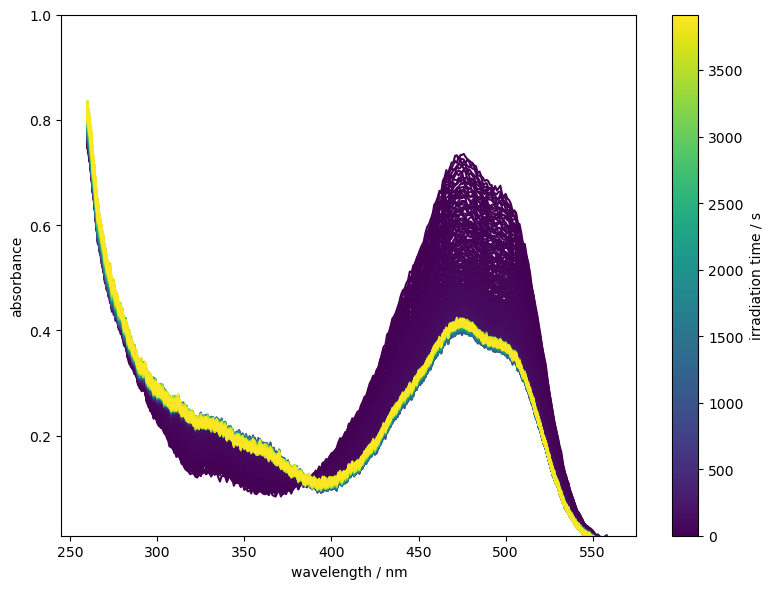

In [7]:
plot_spectra(df_masked,
             ymin=0.01,
             ymax=1)

70506.0


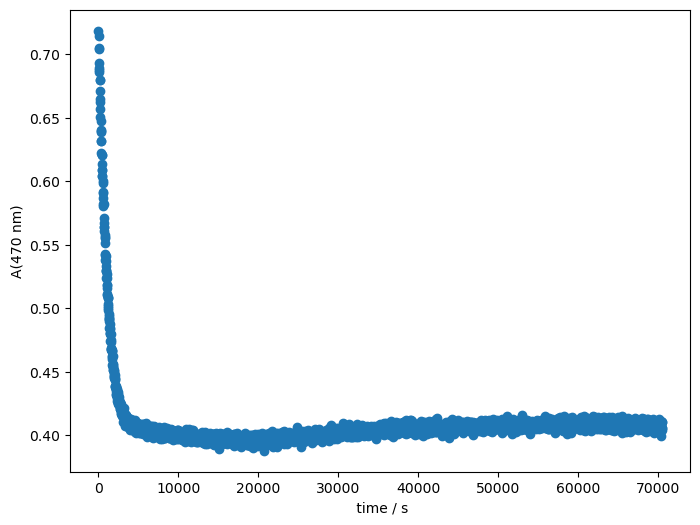

In [6]:
target_wl = 470
time_steps = 0.3 # min
wl_index_series = (df.iloc[:, 0] - target_wl).abs().argmin()

time_points = df.shape[1]-1
times = []
for i in range(0,time_points):
    time = i*time_steps*60
    times.append(time)

print(times[-1])

plt.figure(figsize=(8,6))
plt.xlabel(' time / s')
# plt.xlim(0,3600)
plt.ylabel(f'A({target_wl} nm)')
plt.scatter(times, df.iloc[wl_index_series,1:])
plt.show()